# Function 1 - Week 4: model predictions

A learning study built from this week's **13 real observations**, including the Week 3 return received on 14 October 2026.
Start with [exploration](exploration.ipynb) for the measured outputs, input coverage and saved query sequence.
This notebook examines fitted surfaces, contour maps, uncertainty and target-treatment experiments.

The sequence is: learn the prediction picture on an invented example; choose a useful target scale; compare models on hidden observations;
read real prediction curves and their uncertainty; then interpret contour maps and an acquisition score.
Each step keeps **observations**, **predictions**, **uncertainty** and **query choices** distinct.
The saved coverage sequence still drives the next query. These model experiments do not establish that exploration is complete.

Run this notebook independently with the capstone-local `.venv` and this Week 4 directory as the working directory.
Shared [model helpers](../../Shared/model_helpers.py) and
[two-input plots](../../Shared/two_input_model_helpers.py) keep each teaching step short.

Function 1's signed-log target transform lives in
[FunctionSpecificShared](../FunctionSpecificShared/function_1_model_helpers.py).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
if not (week_dir / "model_predictions.ipynb").is_file() or not (week_dir / "observations.csv").is_file():
    raise FileNotFoundError("Run from Function_1/Week_04 with model_predictions.ipynb and observations.csv together.")
shared_dir = week_dir.parents[1] / "Shared"
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
function_shared_dir = week_dir.parent / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))
from function_1_model_helpers import signed_log
from query_budget import remaining_queries
from model_helpers import (
    make_models, compare_models, plot_toy_sequence, plot_validation,
    gp_slice, make_query_candidates, score_query_candidates,
)
from plot_helpers import PLOT_CONFIG
from two_input_model_helpers import (
    plot_gp_slice, prediction_grid, plot_contour_comparison, plot_gp_maps, fitted_terrain,
)
figures = week_dir / "figures"
figures.mkdir(exist_ok=True)
print("Kernel:", sys.executable)


Kernel: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


## 1. Start from the observations and the existing plan

Load the same CSV as exploration. No new course evaluations are made here.
The two unevaluated coverage points retain their order: their future outputs are unknown.
The remaining weekly allowance counts opportunities, not a confidence score or an exploration-completion percentage.


In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ["x1", "x2"]
X = data[input_columns]
y = data["y"]
inputs = X.to_numpy(dtype=float)
raw_y = y.to_numpy(dtype=float)
if not np.isfinite(np.column_stack([inputs, raw_y])).all() or not ((inputs >= 0) & (inputs < 1)).all():
    raise ValueError("Expected finite observations with both inputs in [0, 1).")
print(f"Observations: {len(data)}; negative outputs: {(raw_y < 0).sum()}; positive outputs: {(raw_y > 0).sum()}.")
print(f"Queries available from the start of Week 4: {remaining_queries(week_dir)} (including this week).")


Observations: 13; negative outputs: 5; positive outputs: 8.
Queries available from the start of Week 4: 10 (including this week).


In [3]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.15308205385104573, 0.13395525138390008], [0.7818589422435338, 0.0256071460565101], [0.12954929624948736, 0.822189245547224], [0.9121401448788213, 0.8617829948823881]],
    columns=input_columns,
)

# The first two planned points were evaluated in rounds 2 and 3.
coverage_queries = planned_queries.iloc[2:].copy()
coverage_queries

planned_inputs = coverage_queries.to_numpy(dtype=float)
print("Coverage sequence retained; the first row remains next:")
display(coverage_queries)


Coverage sequence retained; the first row remains next:


,x1,x2
2,0.129549,0.822189
3,0.912140,0.861783


## 2. Learn the picture before using it on the black box

The blue line is the GP's **posterior mean**: its central prediction after seeing observations.
The pale band is **mean plus or minus 1.96 standard deviations**: a pointwise interval for the latent function under the model's assumptions.
It is not a simultaneous guarantee for the whole curve, and it excludes fresh observation noise.
Green crosses are measured values at the displayed inputs.

Only in this invented one-input example can we also draw the orange dashed **known function**.
The three panels use 3, 6 and 10 points from a fixed invented sequence. They demonstrate updating a model, not a query-selection policy.
None of these points uses the course query allowance. The GP's kernel, noise level and prior scale stay fixed across the panels.

The same visual convention is used in [scikit-learn's introductory GP example](https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_noisy_targets.html).
For the actual black box we have observations and predictions, but no known orange truth curve.


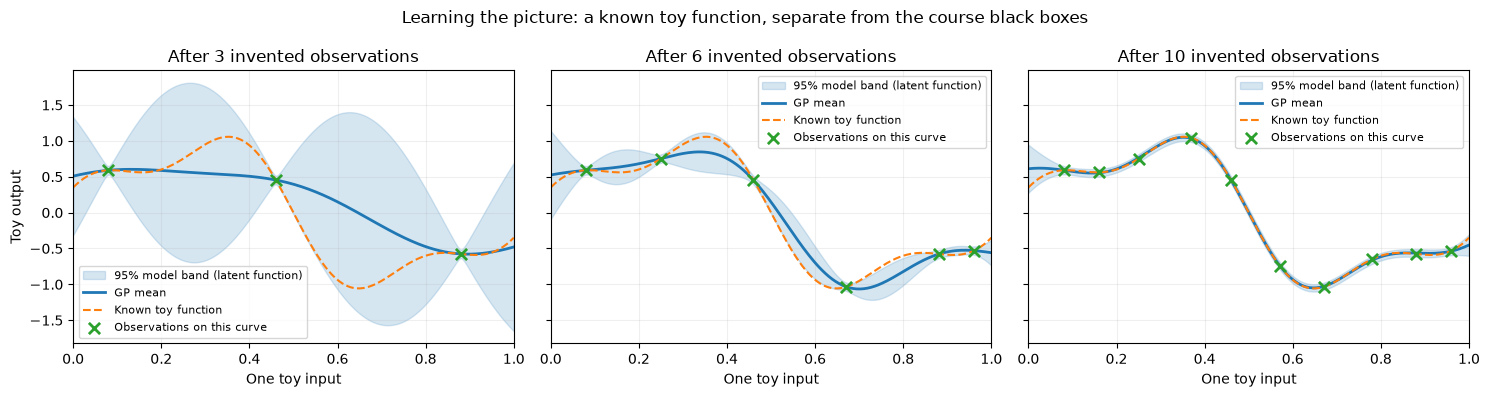

In [4]:
display(plot_toy_sequence(save_to=figures / "gp-picture-toy-sequence.png"))


## 3. Choose what the model is predicting

Function 1 mixes signs and spans roughly 197 orders of magnitude. A raw-output fit would mainly respond to the two large negative magnitudes.
Retain the signed-log height used in exploration:

$$h(y) = \operatorname{sign}(y)\log_{10}(1 + |y| / s), \qquad s = 10^{-200}.$$

This fixed plotting convention preserves signs and ordering; it changes distances and the errors that fitting tries to minimise.
We declare `s` once and do not tune it using validation. Held-out checks below assess prediction on this fixed transformed scale,
not the full process of choosing a transformation or prediction accuracy in raw output units.

Every GP mean, standard deviation and score below is in **height units h**. Transforming a GP mean back would not give the mean raw output.
The original CSV and `y` remain unchanged.


In [5]:
height_scale = 1e-200
height_y = signed_log(raw_y, scale=height_scale)
best_position = int(np.argmax(raw_y))
anchor = inputs[best_position].copy()
observation_review = data[["observation_id", "x1", "x2", "y"]].copy()
observation_review["height_h"] = height_y
display(observation_review)


,observation_id,x1,x2,y,height_h
0,initial-001,0.319404,0.762959,1.322677e-79,121.121454
1,initial-002,0.574329,0.879898,1.033078e-46,154.014133
2,initial-003,0.731024,0.733000,7.710875e-16,184.887104
3,initial-004,0.840353,0.264732,3.341771e-124,76.523977
4,initial-005,0.650114,0.681526,-3.606063e-03,-197.557033
5,initial-006,0.410437,0.147554,-2.159249e-54,-146.334303
6,initial-007,0.312691,0.078723,-2.089093e-91,-109.319958
7,initial-008,0.683418,0.861057,2.535001e-40,160.403978
8,initial-009,0.082507,0.403488,3.606771e-81,119.557119
9,initial-010,0.883890,0.582254,6.229856e-48,152.794478


## 4. State competing models, then hide one result at a time

- **Mean baseline:** ignore the inputs and predict the training outputs' average height.
- **Linear ridge:** fit a tilted plane, with a penalty that restrains large coefficients.
- **Quadratic ridge:** add `x1²`, `x1*x2` and `x2²`, allowing broad curvature and an interaction.
- **Local GP:** assume nearby inputs share information over an RBF length scale of `0.15`.
- **Broad GP:** repeat with length scale `0.35`, sharing information over larger distances.

Both ridge penalties are fixed at `alpha=1.0`. The GP noise SD is assumed to be 10% of the training height SD.
Targets are normalised inside each GP fit; feature scaling for ridge is also refitted inside each training fold.
The GP settings are declared teaching assumptions, not fitted truths or the result of a hyperparameter search.

**Leave-one-out (LOO)** means each prediction hides its own observation and trains on the other 12.
Lower MAE or RMSE is better. `MAE / baseline < 1` beats the mean on this small-sample check.
Training error shows how well a model represents points it has already seen; it is not the same evidence.


In [6]:
models = make_models()
comparison, held_out, fitted = compare_models(models, inputs, height_y)
display(comparison.sort_values("LOO MAE").round(2))
print("These are fixed comparisons on 13 observations, not an independently tested model-selection result.")

best_checked_model = comparison["LOO MAE"].idxmin()
print("Lowest held-out MAE among these fixed comparisons:", best_checked_model)
print("Quadratic / local GP MAE:", round(comparison.loc["Quadratic ridge", "LOO MAE"], 1),
      "/", round(comparison.loc["GP: local (l=0.15)", "LOO MAE"], 1))


,Training MAE,LOO MAE,LOO RMSE,MAE / baseline
Model,,,,
Quadratic ridge,72.38,96.48,127.93,0.68
GP: local (l=0.15),3.21,111.29,140.41,0.79
Linear ridge,90.87,113.02,141.17,0.80
GP: broad (l=0.35),27.40,113.45,131.97,0.80
Mean baseline,130.30,141.16,152.53,1.00


These are fixed comparisons on 13 observations, not an independently tested model-selection result.
Lowest held-out MAE among these fixed comparisons: Quadratic ridge
Quadratic / local GP MAE: 96.5 / 111.3


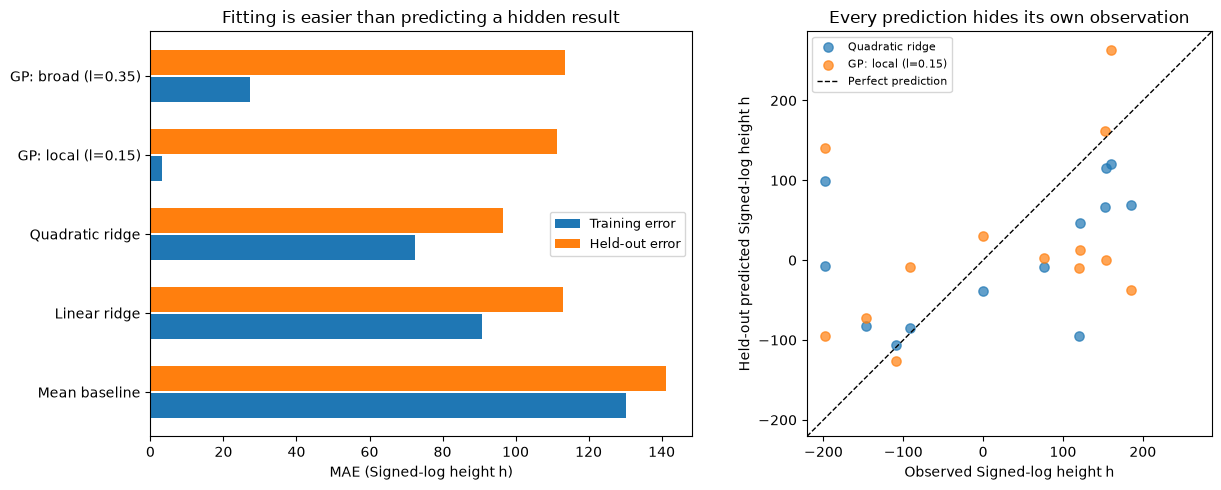

In [7]:
display(plot_validation(comparison, held_out, height_y,
                        save_to=figures / "model-comparison-validation.png"))


## 5. Repeat the prediction picture: vary x1, hold x2 fixed

Use the best observed input as a reference location. Vary `x1` and hold its `x2` coordinate fixed.
This makes a one-dimensional **slice through the two-input model**.
The left panel shows that path; its dotted boundary encloses the sampled inputs.
The right repeats the blue mean, pale band and green measurements from the toy example.

Only measurements whose `x2` actually matches the held value appear as green crosses on this curve.
Other observations still influence the joint GP; they remain on the input map rather than being falsely projected onto the slice.
The curve spans the full input interval, so parts outside the sampled boundary are extrapolations.

Use the local GP for this illustration; it is not automatically the best model in the validation table.
A narrow band expresses this model's confidence, which can still be misplaced if its assumptions are wrong.

The three real-data curve pictures share vertical limits, so their apparent heights and band widths can be compared directly.


Reference input: x1=0.731024, x2=0.733000; observed y=7.710875e-16
Local GP held-out MAE / baseline: 0.788


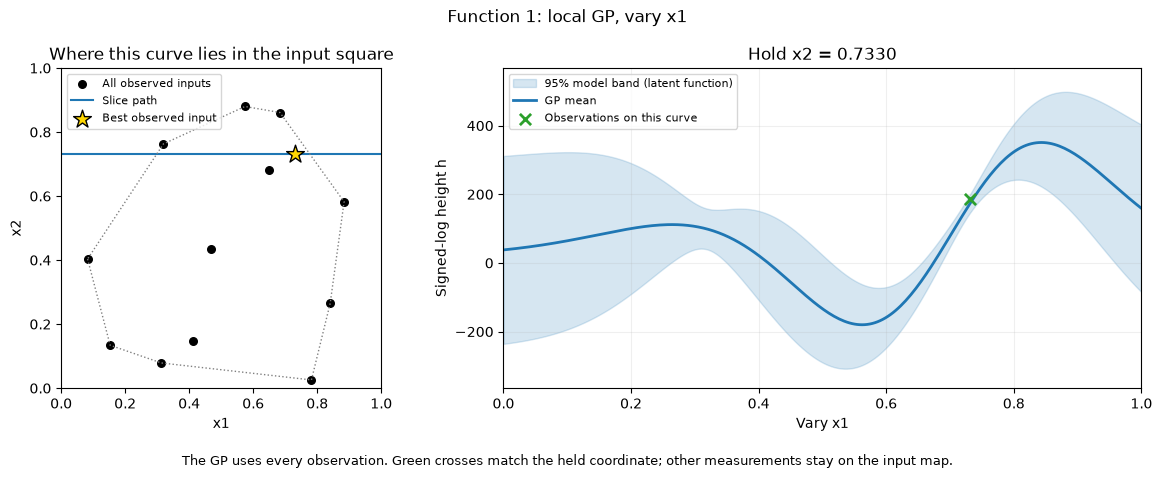

In [8]:
local_gp = fitted["GP: local (l=0.15)"]
broad_gp = fitted["GP: broad (l=0.35)"]
# Keep identical vertical limits across all three repeated curve pictures.
sections_for_limits = [gp_slice(model, inputs, height_y, anchor, axis)
                       for model, axis in [(local_gp, 0), (local_gp, 1), (broad_gp, 0)]]
curve_min = min(np.min(section["mean"] - 1.96 * section["std"]) for section in sections_for_limits)
curve_max = max(np.max(section["mean"] + 1.96 * section["std"]) for section in sections_for_limits)
curve_padding = 0.05 * (curve_max - curve_min)
slice_height_limits = (curve_min - curve_padding, curve_max + curve_padding)
print(f"Reference input: x1={anchor[0]:.6f}, x2={anchor[1]:.6f}; observed y={raw_y[best_position]:.6e}")
print("Local GP held-out MAE / baseline:", round(comparison.loc["GP: local (l=0.15)", "MAE / baseline"], 3))
display(plot_gp_slice(local_gp, inputs, height_y, anchor, 0,
    height_limits=slice_height_limits, title="Function 1: local GP, vary x1", save_to=figures / "gp-slice-x1-local.png"))


## 6. Repeat it again: vary x2, hold x1 fixed

Now move in the other input direction through the same reference point.
The model and observations are unchanged; only the path through the input square changes.
Read the same three elements again: mean, model band and measurements actually on the slice.
Differences between the two curves describe the fitted input relationship, not a known property of the black box.


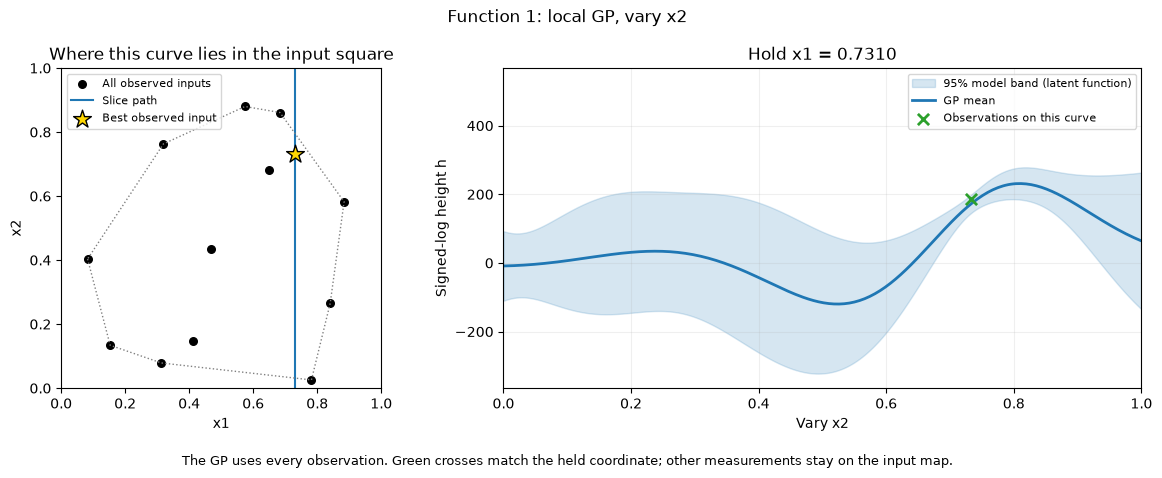

In [9]:
display(plot_gp_slice(local_gp, inputs, height_y, anchor, 1,
    height_limits=slice_height_limits, title="Function 1: local GP, vary x2", save_to=figures / "gp-slice-x2-local.png"))


## 7. Change an assumption, then repeat the first slice

Return to varying `x1`, now with the broad GP. Its larger length scale shares information between more distant inputs.
Compare this picture with Section 5 and compare their held-out errors in Section 4.
An appealing smooth curve is not evidence by itself. The band reflects the chosen kernel and noise assumptions;
it does not include uncertainty about which model or target transformation is appropriate.

The GP noise parameter and returned standard deviation follow the [GaussianProcessRegressor documentation](https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html).

Both GPs can overshoot the measured height range between observations or outside the sampled region.
On this chosen transform, `h = 200` corresponds approximately to raw `y = 1`; substantially larger heights
would imply enormous raw values compared with the current observations. These are unconstrained model outputs,
not evidence that such a peak exists. Smoothness and a narrow band do not resolve this target-scale sensitivity.


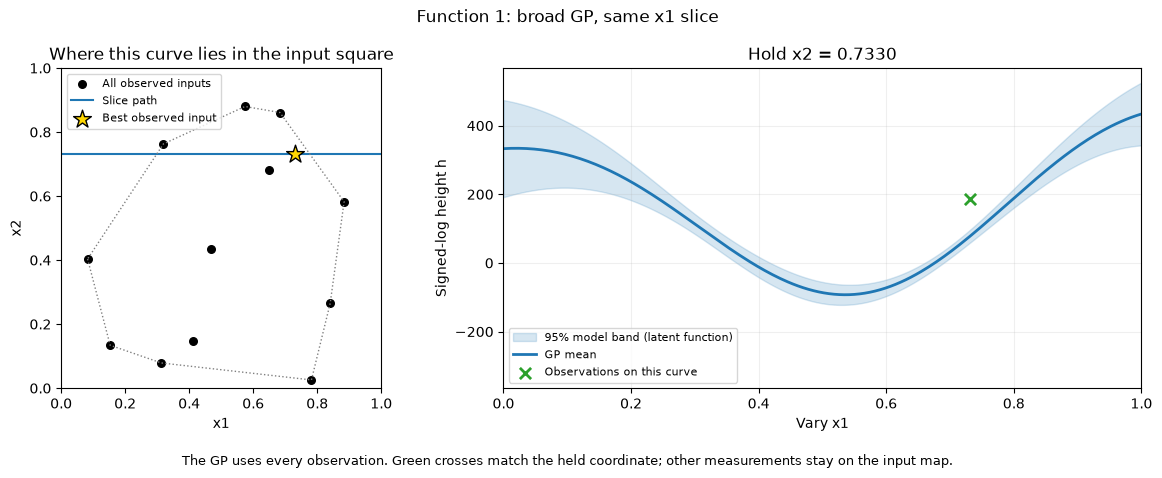

In [10]:
display(plot_gp_slice(broad_gp, inputs, height_y, anchor, 0,
    height_limits=slice_height_limits, title="Function 1: broad GP, same x1 slice", save_to=figures / "gp-slice-x1-broad.png"))


## 8. From curves to contour maps

A curve examined one path. A **contour** joins locations in the input square with the same fitted height.
Its number is a height `h`, not a raw output, observation rank or uncertainty.
Closer contours indicate a steeper change in the fitted mean. The colours fill the bands between levels.

The quadratic from the earlier exploration experiment and the local GP now predict on the same regular grid.
The panels share colour limits and contour levels. Coloured dots are observations on that same height scale;
colour differences between a dot and its background expose a fitting mismatch.
Blank regions are outside the sampled convex hull; interior gaps still have model uncertainty.
The right map shows a GP **mean**, not its uncertainty. Keep the validation table in view when interpreting either surface.


Quadratic h = -76.01 -243.80*x1 +106.55*x2 +405.98*x1^2 -146.73*x1 x2 +241.45*x2^2


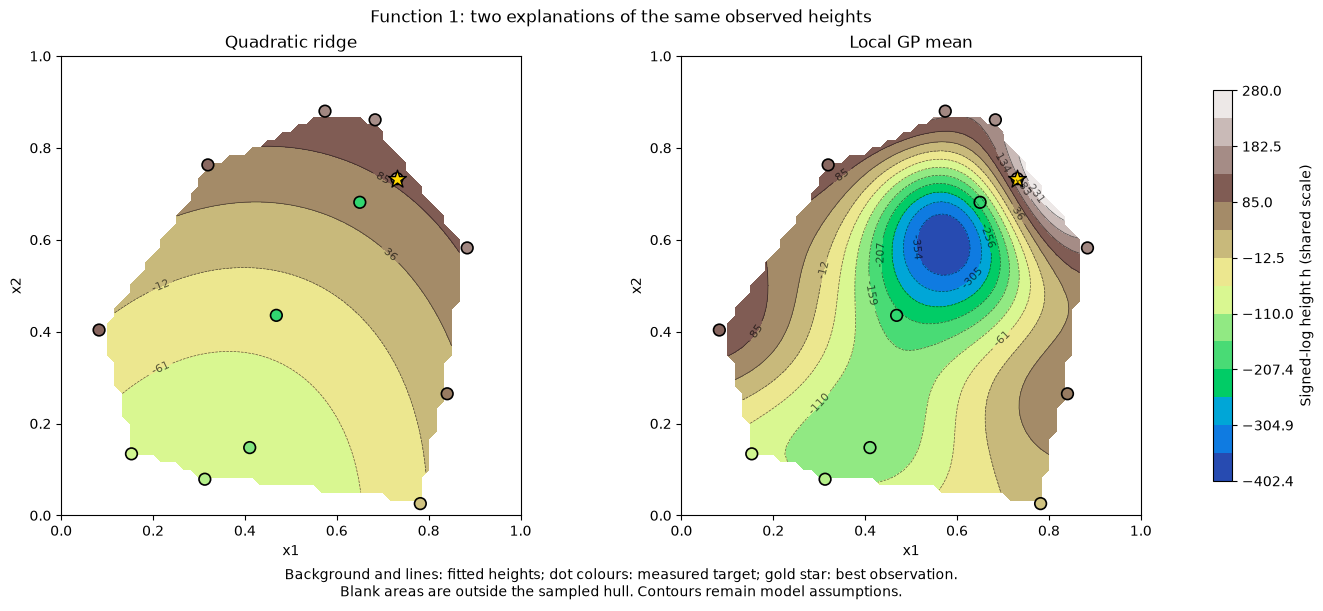

In [11]:
# Express the quadratic in the original input coordinates, undoing feature scaling.
quadratic = fitted["Quadratic ridge"]
feature_scaler = quadratic.named_steps["standardscaler"]
regression = quadratic.named_steps["ridge"]
coefficients = regression.coef_ / feature_scaler.scale_
intercept = regression.intercept_ - coefficients @ feature_scaler.mean_
terms = quadratic.named_steps["polynomialfeatures"].get_feature_names_out(input_columns)
print("Quadratic h = " + f"{intercept:.2f}" + "".join(
    f" {coefficient:+.2f}*{term}" for coefficient, term in zip(coefficients, terms)))

quadratic_grid = prediction_grid(fitted["Quadratic ridge"], inputs)
gp_grid = prediction_grid(local_gp, inputs, uncertainty=True)
display(plot_contour_comparison(inputs, [
    ("Quadratic ridge", quadratic_grid, height_y),
    ("Local GP mean", gp_grid, height_y),
], title="Function 1: two explanations of the same observed heights",
   save_to=figures / "fitted-output-contours.png"))
quadratic_terrain = fitted_terrain(quadratic_grid, inputs, height_y, raw_y,
    title="Function 1: quadratic model predictions (signed-log height)",
    save_to=figures / "fitted-output-terrain.html")
quadratic_terrain.show(config=PLOT_CONFIG)


## 9. Separate a high prediction from high uncertainty

Read the next panels from left to right: the GP mean, its standard deviation, then an illustrative upper confidence bound:

$$\operatorname{UCB}(x) = \mu(x) + \kappa\sigma(x), \qquad \kappa = 1.96.$$

A high UCB can come from a promising mean, substantial uncertainty, or both. It is an **acquisition score**, not a predicted output
or a guarantee of improvement. The weight is a declared heuristic. Its numerical agreement with the band multiplier does not prove an optimal policy.

Here the full input square is coloured so uncertainty outside the sampled hull is visible. The dotted outline marks that hull;
coloured areas outside it are explicit extrapolations. Each panel has its own units and colour scale.
The gold star remains the next **saved coverage point**, rather than a model-selected replacement.
The table evaluates the remaining coverage inputs without changing their order.


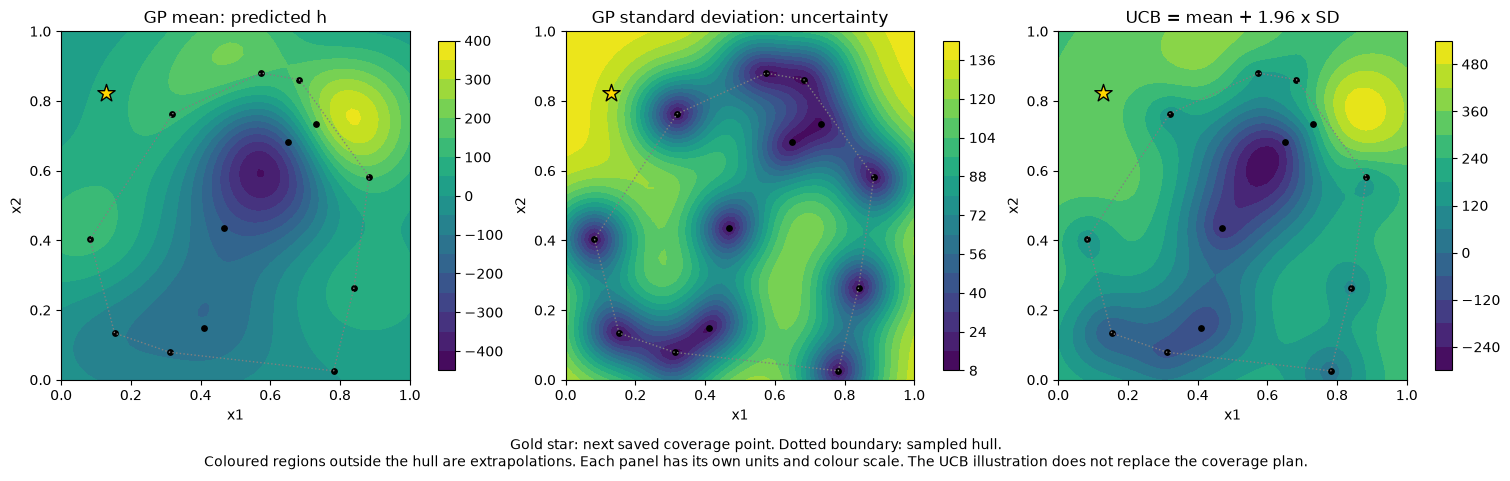

,x1,x2,GP mean h,GP SD h,Illustrative UCB
2,0.129549,0.822189,67.231270,127.685741,317.495323
3,0.912140,0.861783,198.615099,124.735957,443.097574


Next query remains the first saved coverage point: 0.129549-0.822189.


In [12]:
exploration_weight = 1.96
display(plot_gp_maps(gp_grid, inputs, planned_inputs, weight=exploration_weight,
                     save_to=figures / "gp-mean-uncertainty-ucb.png"))
plan_mean, plan_std = local_gp.predict(planned_inputs, return_std=True)
plan_review = coverage_queries.copy()
plan_review["GP mean h"] = plan_mean
plan_review["GP SD h"] = plan_std
plan_review["Illustrative UCB"] = plan_mean + exploration_weight * plan_std
display(plan_review)
print("Next query remains the first saved coverage point: 0.129549-0.822189.")


## 10. If we switched today: a hypothetical model-led next query

Choose the lower-LOO-MAE **GP** among the two fixed GP comparisons, then maximise
`mean + 1.96 * SD` over a declared finite candidate pool. A GP supplies both the mean and uncertainty
needed for this rule; the lowest-error model overall may still be a different regressor.
This is a transparent counterfactual policy, not proof that the GP or its settings are optimal.
Selecting a model using these same 13 observations can make its reported error optimistic.

The pool contains 4,096 seeded Sobol points plus the four allowed extreme corners.
Round inputs to six decimals **before predicting**, remove duplicates and already observed coordinates,
then score those exact inputs. The winner is the best of this finite pool, not a proven continuous optimum.
Candidates outside the sampled hull are permitted and explicitly labelled as extrapolations.

The table reports a single suggested input, its posterior mean, standard deviation and UCB in the model's target units.
A second table changes only the exploration weight, reusing the same predictions. Weight zero chooses the highest mean.
The magenta X marks the hypothetical query; the gold star remains the saved coverage choice.
No new course evaluation is made, and the actual Week 4 query plan remains unchanged.

The chosen GP's MAE ratio is printed beside the suggestion. A ratio of 1 or more means it does not beat the mean baseline; the hypothetical query then lacks even that predictive support.


Hypothetical GP policy: GP: local (l=0.15)
Chosen GP held-out MAE / mean baseline: 0.788
Lowest-error model overall: Quadratic ridge
Candidate count after rounding and exclusions: 4,100
Suggested model-led input (counterfactual): 0.876772-0.780703
Target units: signed-log height h; these are not mean raw-output predictions.
Posterior mean: 327.470660; SD: 96.765124; UCB: 517.130302
Inside sampled hull: False


,x1,x2,posterior_mean,posterior_sd,ucb
0,0.876772,0.780703,327.470660,96.765124,517.130302
1,0.882335,0.782668,320.695359,99.824695,516.351761
2,0.865907,0.776811,338.911608,90.429811,516.154036
3,0.868276,0.763758,342.820040,87.968283,515.237874
4,0.889150,0.759836,324.108722,96.761674,513.761604


,Weight,x1,x2,Mean,SD,Score
0,0.00,0.842297,0.758028,355.658588,72.325076,355.658588
1,1.00,0.868276,0.763758,342.820040,87.968283,430.788323
2,1.96,0.876772,0.780703,327.470660,96.765124,517.130302
3,3.00,0.892267,0.794645,300.532319,106.934295,621.335203


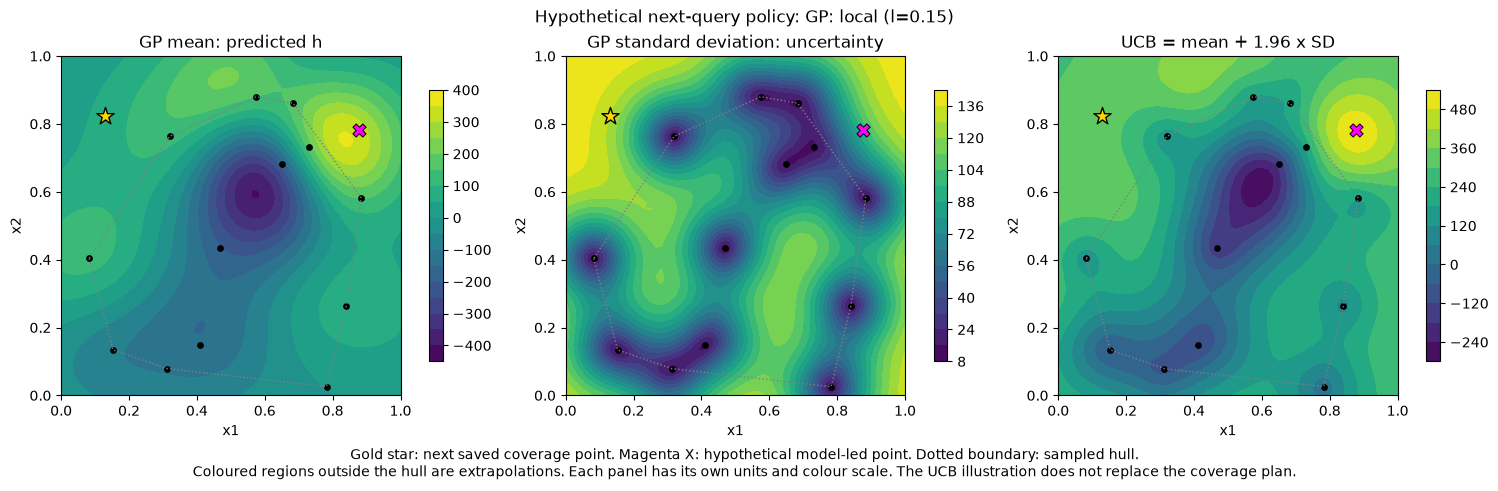

Actual coverage-led input remains: 0.129549-0.822189


In [13]:
# The GP choice is explicit, even if a different regression has lower held-out error.
gp_names = [name for name in comparison.index if name.startswith("GP:")]
proposal_gp_name = comparison.loc[gp_names, "LOO MAE"].idxmin()
proposal_gp = fitted[proposal_gp_name]
query_candidates = make_query_candidates(inputs, power=12, seed=42)
scored_candidates = score_query_candidates(proposal_gp, query_candidates, weight=exploration_weight)
hypothetical_query = scored_candidates.iloc[0].copy()
hypothetical_inputs = hypothetical_query[["x1", "x2"]].to_numpy(dtype=float)
hypothetical_portal_input = "-".join(f"{value:.6f}" for value in hypothetical_inputs)
from scipy.spatial import Delaunay
hypothetical_inside_hull = bool(Delaunay(inputs).find_simplex(hypothetical_inputs) >= 0)
proposal_relative_error = comparison.loc[proposal_gp_name, "MAE / baseline"]
print("Hypothetical GP policy:", proposal_gp_name)
print(f"Chosen GP held-out MAE / mean baseline: {proposal_relative_error:.3f}")
if proposal_relative_error >= 1:
    print("Predictive check: this GP performs worse than the mean baseline; its suggested point is illustrative.")
print("Lowest-error model overall:", best_checked_model)
print(f"Candidate count after rounding and exclusions: {len(scored_candidates):,}")
print("Suggested model-led input (counterfactual):", hypothetical_portal_input)
print("Target units: signed-log height h; these are not mean raw-output predictions.")
print(f"Posterior mean: {hypothetical_query['posterior_mean']:.6f}; SD: {hypothetical_query['posterior_sd']:.6f}; UCB: {hypothetical_query['ucb']:.6f}")
print("Inside sampled hull:", hypothetical_inside_hull)
display(scored_candidates.head(5))

# Reuse these GP predictions: no refits or extra course queries for the sensitivity table.
weight_sensitivity = []
for weight in [0.0, 1.0, 1.96, 3.0]:
    scores = scored_candidates["posterior_mean"] + weight * scored_candidates["posterior_sd"]
    alternative = scored_candidates.loc[scores.idxmax()]
    weight_sensitivity.append({"Weight": weight, "x1": alternative["x1"], "x2": alternative["x2"],
        "Mean": alternative["posterior_mean"], "SD": alternative["posterior_sd"],
        "Score": alternative["posterior_mean"] + weight * alternative["posterior_sd"]})
display(pd.DataFrame(weight_sensitivity))
proposal_grid = prediction_grid(proposal_gp, inputs, uncertainty=True)
display(plot_gp_maps(proposal_grid, inputs, planned_inputs, weight=exploration_weight,
    suggestion=hypothetical_inputs, title=f"Hypothetical next-query policy: {proposal_gp_name}",
    save_to=figures / "model-query-proposal.png"))
print("Actual coverage-led input remains:", "-".join(f"{value:.6f}" for value in planned_inputs[0]))


## 11. Target sensitivity: what if negative outputs count as zero?

Consider a separate modelling question:

$$y_+ = \max(y, 0), \qquad h_+ = \log_{10}(1 + y_+ / s).$$

Five negative observations share a zero baseline; eight positives keep their original heights.
Keep all 13 rows and refit the same quadratic. Floor negative fitted heights at zero for both plotting and held-out checks.
This floor is explicit post-processing, not a non-negativity constraint on the quadratic's coefficients.

The target and error scale have changed. Comparing a new error number with the original MAE would not establish better prediction of the original outputs.
Nothing here establishes that the negative measurements were wrong. The CSV, original target and coverage plan are preserved.


In [14]:
nonnegative_y = np.maximum(raw_y, 0.0)
nonnegative_heights = signed_log(nonnegative_y, scale=height_scale)
zero_models = {name: models[name] for name in ("Mean baseline", "Quadratic ridge")}
zero_comparison, zero_held_out, zero_fitted = compare_models(
    zero_models, inputs, nonnegative_heights, floor_zero=True,
)
print(f"Negative outputs treated as zero: {(raw_y < 0).sum()} of {len(raw_y)}")
display(zero_comparison.round(2))
nonnegative_grid = prediction_grid(zero_fitted["Quadratic ridge"], inputs, floor_zero=True)


Negative outputs treated as zero: 5 of 13


,Training MAE,LOO MAE,LOO RMSE,MAE / baseline
Model,,,,
Mean baseline,68.79,74.52,79.19,1.00
Quadratic ridge,30.09,40.67,55.85,0.55


## 12. Compare the two targets with the same contour scale

The left panel refits the original signed heights; the right refits the modified target.
All contour levels and colours are shared. Any change therefore comes from the target treatment and its refit,
rather than an independently rescaled palette. The draggable view retains the modified observations as markers.


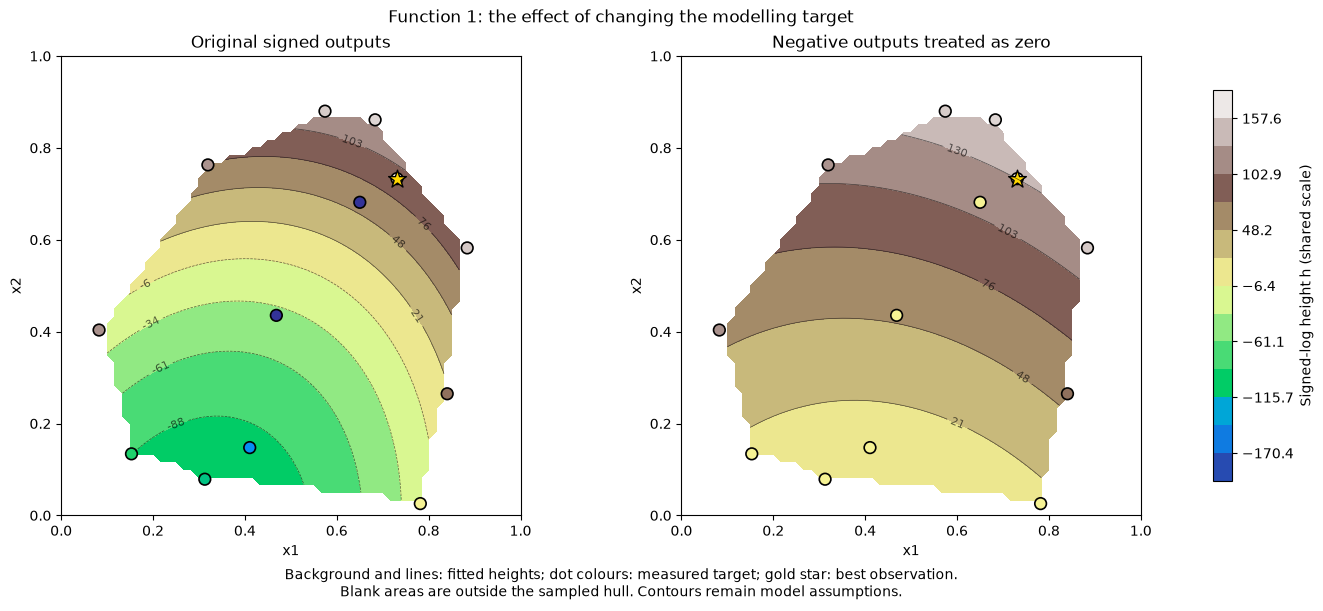

In [15]:
display(plot_contour_comparison(inputs, [
    ("Original signed outputs", quadratic_grid, height_y),
    ("Negative outputs treated as zero", nonnegative_grid, nonnegative_heights),
], title="Function 1: the effect of changing the modelling target",
   save_to=figures / "nonnegative-output-contours-comparison.png"))
nonnegative_terrain = fitted_terrain(nonnegative_grid, inputs, nonnegative_heights, raw_y,
    title="Function 1: modified-target quadratic predictions (negatives treated as zero)",
    save_to=figures / "nonnegative-output-terrain.html")
nonnegative_terrain.show(config=PLOT_CONFIG)


## Read the pictures in the same order each time

1. Identify the input path or plane, target scale and measured observations.
2. Read the fitted mean before looking at its band or contour colours.
3. Name the assumptions behind the uncertainty and check hidden-result errors against the mean baseline.
4. Separate a predicted response from an acquisition score and the actual query policy.

The working evidence is a small comparison on 13 observations. Reusing these observations to choose among models can make the winning error optimistic.
No picture supplies the unknown true surface or proves that a predicted optimum is real.
For Week 4, the [exploration notebook's coverage sequence](exploration.ipynb) remains the query decision;
these model studies provide practice and hypotheses to revisit with future observations.
